# Model evaluation metrics — Code-Along Template

**Type into this notebook during class.** The explanation is here; the code is not.

| | |
|---|---|
| **Follow along** | Write the code in each `# TODO` cell. The hint names the functions and arguments. |
| **If you fall behind** | Do not copy frantically. Skip to the next **CHECKPOINT**, run it, rejoin. |
| **If a cell errors** | Later cells depend on it and will fail too. Run the next CHECKPOINT rather than debugging under time pressure. |
| **After class** | The worked version is `D008_C8_Model_Evaluation_Metrics.ipynb`. Compare, do not copy. |

Cells that are already filled in are deliberate — imports and quick glances at the
data cost class time and teach nothing.

# Chapter 8: Model Evaluation Metrics

> **Data** generated inline  (exercises use clinic_readmission.csv) · **Time** 120 min · **Needs first** C1b for the imbalance material

## What you will be able to do

1. Read a confusion matrix and compute precision, recall, F1 and specificity from it
2. Choose between precision, recall and F1 for a stated cost of error
3. Read an ROC curve and a precision-recall curve, and say when each is the right one
4. Compare regression models with MAE, RMSE and R-squared, and explain a disagreement between them
5. Diagnose a fitted model from its residual plot
6. Choose k from a silhouette plot and an elbow curve
7. Diagnose overfitting and underfitting from training curves

## The one idea to hold on to

A metric encodes what you are willing to be wrong about. Choose it before you fit anything, or you will choose it afterwards to suit the number you got.

## A Comprehensive Guide to Understanding and Interpreting ML Metrics

---

**Learning Objectives:**
- Understand why accuracy alone is insufficient for model evaluation
- Master classification metrics: Confusion Matrix, Precision, Recall, F1, ROC-AUC
- Learn regression metrics: MAE, MSE, RMSE, R-squared
- Explore clustering metrics: Silhouette Score, Davies-Bouldin Index
- Interpret evaluation curves and visualizations
- Choose the right metric for different problem types

**Duration:** ~2 hours

**Prerequisites:** Module 03 (Statistics), Module 04 (Preprocessing basics)

## 1. Introduction: Why Evaluation Metrics Matter

### The Accuracy Trap

Imagine a model predicting credit card fraud where only 1% of transactions are fraudulent:

| Model | Prediction | Accuracy |
|-------|------------|----------|
| Model A | Predicts "Not Fraud" for everything | 99% |
| Model B | Actually detects 80% of fraud cases | 98.5% |

**Model A has higher accuracy but is completely useless!** It catches zero fraud cases.

This is why we need multiple evaluation metrics that capture different aspects of model performance.

### Metric Categories

| Problem Type | Key Metrics |
|--------------|-------------|
| **Classification** | Accuracy, Precision, Recall, F1-Score, ROC-AUC |
| **Regression** | MAE, MSE, RMSE, R-squared |
| **Clustering** | Silhouette Score, Davies-Bouldin, Calinski-Harabasz |

In [ ]:
# TODO: draw a `plt.style.use`

---

## 2. Classification Metrics

### 2.1 The Confusion Matrix

The confusion matrix is the foundation of all classification metrics.

```
                    PREDICTED
                 Negative  Positive
            +-----------+-----------+
  ACTUAL    |    TN     |    FP     |   Negative
            +-----------+-----------+
            |    FN     |    TP     |   Positive
            +-----------+-----------+
```

**Understanding Each Cell:**

| Term | Full Name | Meaning | Example (Fraud Detection) |
|------|-----------|---------|---------------------------|
| **TP** | True Positive | Correctly predicted positive | Fraud correctly flagged |
| **TN** | True Negative | Correctly predicted negative | Legitimate correctly passed |
| **FP** | False Positive | Incorrectly predicted positive | Legitimate flagged as fraud (Type I Error) |
| **FN** | False Negative | Incorrectly predicted negative | Fraud missed (Type II Error) |

In [ ]:
# TODO: compute `n_samples`, `n_features`, `n_informative`
# Name your result: n_samples, n_features, n_informative, n_redundant

In [ ]:
# TODO: compute `cm`, `xticklabels`, `yticklabels`
# Name your result: cm, xticklabels, yticklabels, cm_normalized

In [ ]:
# ═══ CHECKPOINT — "Core Classification Metrics" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, roc_curve, roc_auc_score, precision_recall_curve, auc
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification, make_regression, make_blobs
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
import warnings
X, y = make_classification(n_samples=1000, n_features=10, n_informative=5, n_redundant=2, weights=[0.7, 0.3], random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tn, fp, fn, tp = cm.ravel()
cm_normalized = cm.astype('float') / cm.sum() * 100

print("Checkpoint restored. Ready for: Core Classification Metrics")

### 2.2 Core Classification Metrics

#### Accuracy
$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

**When to use:** Balanced datasets  
**When NOT to use:** Imbalanced datasets (fraud, disease detection)

---

#### Precision (Positive Predictive Value)
$$\text{Precision} = \frac{TP}{TP + FP}$$

**Question it answers:** "Of all predicted positives, how many are actually positive?"

**High precision matters when:** False positives are costly
- Spam detection (don't want to send important emails to spam)
- Legal recommendations (false accusations are costly)

---

#### Recall (Sensitivity, True Positive Rate)
$$\text{Recall} = \frac{TP}{TP + FN}$$

**Question it answers:** "Of all actual positives, how many did we correctly identify?"

**High recall matters when:** False negatives are costly
- Cancer detection (don't want to miss cancer cases)
- Fraud detection (don't want to miss fraud)

---

#### F1-Score
$$\text{F1} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

**Harmonic mean** of precision and recall. Penalizes extreme values.

**When to use:** When you need balance between precision and recall

---

#### Specificity (True Negative Rate)
$$\text{Specificity} = \frac{TN}{TN + FP}$$

**Question it answers:** "Of all actual negatives, how many did we correctly identify?"

In [ ]:
# TODO: compute `accuracy`, `precision`, `recall` from `Metric`, `Formula`, `Value`
# Name your result: accuracy, precision, recall, f1

In [ ]:
# TODO: draw a `plt.subplots`
# Name your result: metrics, values, colors, bars

In [6]:
# Full classification report
print("\n" + "=" * 60)
print("SKLEARN CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))


SKLEARN CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.78      0.95      0.85       193
    Positive       0.84      0.50      0.63       107

    accuracy                           0.79       300
   macro avg       0.81      0.73      0.74       300
weighted avg       0.80      0.79      0.77       300



### 2.3 Multi-Class F1 Variants

For multi-class problems, we have different ways to aggregate F1-Score:

| Variant | Calculation | Best For |
|---------|-------------|----------|
| **Macro F1** | Average of per-class F1 scores | Balanced importance across classes |
| **Weighted F1** | Weighted average by class support | Class imbalance exists |
| **Micro F1** | Global TP, FP, FN aggregation | Overall performance |

In [ ]:
# TODO: compute `n_samples`, `n_classes`, `model_multi`
# Name your result: n_samples, n_classes, model_multi, y_pred_m

In [ ]:
# ═══ CHECKPOINT — "ROC Curve and AUC" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, roc_curve, roc_auc_score, precision_recall_curve, auc
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification, make_regression, make_blobs
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
import warnings
X, y = make_classification(n_samples=1000, n_features=10, n_informative=5, n_redundant=2, weights=[0.7, 0.3], random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tn, fp, fn, tp = cm.ravel()
cm_normalized = cm.astype('float') / cm.sum() * 100
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
specificity = tn / (tn + fp)
metrics_df = pd.DataFrame({'Metric': ['Accuracy', 'Precision', 'Recall (Sensitivity)', 'Specificity', 'F1-Score'], 'Formula': ['(TP+TN) / (TP+TN+FP+FN)', 'TP / (TP+FP)', 'TP / (TP+FN)', 'TN / (TN+FP)', '2 * (Prec*Rec) / (Prec+Rec)'], 'Value': [accuracy, precision, recall, specificity, f1], 'Interpretation': [f'{accuracy:.1%} of all predictions were correct', f'{precision:.1%} of predicted positives were correct', f'{recall:.1%} of actual positives were found', f'{specificity:.1%} of actual negatives were identified', f'Harmonic mean balancing precision and recall']})
fig, ax = plt.subplots(figsize=(10, 6))
metrics = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1-Score']
values = [accuracy, precision, recall, specificity, f1]
colors = ['#2ecc71', '#3498db', '#e74c3c', '#9b59b6', '#f39c12']
bars = ax.barh(metrics, values, color=colors, edgecolor='black', linewidth=1.5)
X_multi, y_multi = make_classification(n_samples=1000, n_features=10, n_informative=5, n_classes=3, n_clusters_per_class=1, random_state=42)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y_multi, test_size=0.3, random_state=42)
model_multi = LogisticRegression(random_state=42, max_iter=1000)
model_multi.fit(X_train_m, y_train_m)
y_pred_m = model_multi.predict(X_test_m)
f1_macro = f1_score(y_test_m, y_pred_m, average='macro')
f1_weighted = f1_score(y_test_m, y_pred_m, average='weighted')
f1_micro = f1_score(y_test_m, y_pred_m, average='micro')

print("Checkpoint restored. Ready for: ROC Curve and AUC")

### 2.4 ROC Curve and AUC

The **ROC (Receiver Operating Characteristic)** curve plots:
- **X-axis:** False Positive Rate (FPR) = FP / (FP + TN)
- **Y-axis:** True Positive Rate (TPR) = Recall = TP / (TP + FN)

**AUC (Area Under the Curve)** Interpretation:

| AUC Value | Interpretation |
|-----------|----------------|
| 1.0 | Perfect classifier |
| 0.9 - 1.0 | Excellent |
| 0.8 - 0.9 | Good |
| 0.7 - 0.8 | Fair |
| 0.5 - 0.7 | Poor |
| 0.5 | Random classifier (no discrimination) |

In [ ]:
# TODO: compute `roc_auc`, `arrowprops`, `xytext`
# Name your result: roc_auc, arrowprops, xytext

### 2.5 Precision-Recall Curve

The **Precision-Recall Curve** is particularly useful for **imbalanced datasets** where ROC-AUC can be misleading.

- **X-axis:** Recall
- **Y-axis:** Precision

**When to prefer PR curve over ROC:**
- Highly imbalanced data (rare positive class)
- When false positives and false negatives have different costs
- When the positive class is what you care about most

In [ ]:
# TODO: compute `pr_auc`, `no_skill`
# Name your result: pr_auc, no_skill

### 2.6 Threshold Selection: Precision-Recall Trade-off

By default, classifiers use 0.5 as the threshold for binary predictions. Adjusting this threshold allows you to trade off between precision and recall.

In [ ]:
# TODO: compute `thresholds_to_try`, `results`, `y_pred_thresh` from `Threshold`, `Precision`, `Recall`
# Name your result: thresholds_to_try, results, y_pred_thresh, results_df

---

## 3. Regression Metrics

### 3.1 Error Metrics Overview

| Metric | Formula | Interpretation |
|--------|---------|----------------|
| **MAE** | $\frac{1}{n}\sum|y_i - \hat{y}_i|$ | Average absolute error (same units as target) |
| **MSE** | $\frac{1}{n}\sum(y_i - \hat{y}_i)^2$ | Squares errors (penalizes large errors more) |
| **RMSE** | $\sqrt{\frac{1}{n}\sum(y_i - \hat{y}_i)^2}$ | Root of MSE (back to original units) |
| **MAPE** | $\frac{100}{n}\sum|\frac{y_i - \hat{y}_i}{y_i}|$ | Percentage error |
| **R-squared** | $1 - \frac{SS_{res}}{SS_{tot}}$ | Proportion of variance explained (0-1) |

In [ ]:
# TODO: compute `reg_model`, `y_pred_r`, `mae`
# Name your result: reg_model, y_pred_r, mae, mse

In [ ]:
# ═══ CHECKPOINT — "R-squared (Coefficient of Determination)" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, roc_curve, roc_auc_score, precision_recall_curve, auc
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification, make_regression, make_blobs
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
import warnings
X, y = make_classification(n_samples=1000, n_features=10, n_informative=5, n_redundant=2, weights=[0.7, 0.3], random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tn, fp, fn, tp = cm.ravel()
cm_normalized = cm.astype('float') / cm.sum() * 100
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
specificity = tn / (tn + fp)
metrics_df = pd.DataFrame({'Metric': ['Accuracy', 'Precision', 'Recall (Sensitivity)', 'Specificity', 'F1-Score'], 'Formula': ['(TP+TN) / (TP+TN+FP+FN)', 'TP / (TP+FP)', 'TP / (TP+FN)', 'TN / (TN+FP)', '2 * (Prec*Rec) / (Prec+Rec)'], 'Value': [accuracy, precision, recall, specificity, f1], 'Interpretation': [f'{accuracy:.1%} of all predictions were correct', f'{precision:.1%} of predicted positives were correct', f'{recall:.1%} of actual positives were found', f'{specificity:.1%} of actual negatives were identified', f'Harmonic mean balancing precision and recall']})
fig, ax = plt.subplots(figsize=(10, 6))
metrics = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1-Score']
values = [accuracy, precision, recall, specificity, f1]
colors = ['#2ecc71', '#3498db', '#e74c3c', '#9b59b6', '#f39c12']
bars = ax.barh(metrics, values, color=colors, edgecolor='black', linewidth=1.5)
X_multi, y_multi = make_classification(n_samples=1000, n_features=10, n_informative=5, n_classes=3, n_clusters_per_class=1, random_state=42)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y_multi, test_size=0.3, random_state=42)
model_multi = LogisticRegression(random_state=42, max_iter=1000)
model_multi.fit(X_train_m, y_train_m)
y_pred_m = model_multi.predict(X_test_m)
f1_macro = f1_score(y_test_m, y_pred_m, average='macro')
f1_weighted = f1_score(y_test_m, y_pred_m, average='weighted')
f1_micro = f1_score(y_test_m, y_pred_m, average='micro')
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)
fig, ax = plt.subplots(figsize=(10, 8))
precision_curve, recall_curve, pr_thresholds = precision_recall_curve(y_test, y_proba)
pr_auc = auc(recall_curve, precision_curve)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
no_skill = sum(y_test) / len(y_test)
thresholds_to_try = np.arange(0.1, 1.0, 0.1)
results = []
for threshold in thresholds_to_try:
    y_pred_thresh = (y_proba >= threshold).astype(int)
    results.append({'Threshold': threshold, 'Precision': precision_score(y_test, y_pred_thresh, zero_division=0), 'Recall': recall_score(y_test, y_pred_thresh), 'F1': f1_score(y_test, y_pred_thresh)})
results_df = pd.DataFrame(results)
fig, ax = plt.subplots(figsize=(12, 6))
best_idx = results_df['F1'].idxmax()
best_threshold = results_df.loc[best_idx, 'Threshold']
best_f1 = results_df.loc[best_idx, 'F1']
X_reg, y_reg = make_regression(n_samples=500, n_features=5, noise=20, random_state=42)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.3, random_state=42)
reg_model = LinearRegression()
reg_model.fit(X_train_r, y_train_r)
y_pred_r = reg_model.predict(X_test_r)
mae = mean_absolute_error(y_test_r, y_pred_r)
mse = mean_squared_error(y_test_r, y_pred_r)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_r, y_pred_r)
mask = y_test_r != 0
mape = np.mean(np.abs((y_test_r[mask] - y_pred_r[mask]) / y_test_r[mask])) * 100

print("Checkpoint restored. Ready for: R-squared (Coefficient of Determination)")

### 3.2 R-squared (Coefficient of Determination)

$$R^2 = 1 - \frac{SS_{residual}}{SS_{total}} = 1 - \frac{\sum(y_i - \hat{y}_i)^2}{\sum(y_i - \bar{y})^2}$$

**Interpretation:**

| R-squared | Interpretation |
|-----------|----------------|
| 1.0 | Perfect fit (all variance explained) |
| 0.9+ | Excellent fit |
| 0.7-0.9 | Good fit |
| 0.5-0.7 | Moderate fit |
| 0.3-0.5 | Weak fit |
| < 0.3 | Poor fit |
| < 0 | Model is worse than predicting mean |

In [ ]:
# TODO: draw a `plt.subplots`
# Name your result: min_val, max_val, residuals, std_residual

### 3.3 Residual Analysis: What to Look For

Residual plots help diagnose model problems:

| Pattern | Problem | Solution |
|---------|---------|----------|
| Random scatter around 0 | Good model fit | None needed |
| Funnel shape | Heteroscedasticity | Transform target, use weighted regression |
| Curved pattern | Non-linearity missed | Add polynomial features |
| Clustered residuals | Model underspecified | Add more features |

In [ ]:
# TODO: compute `x`, `good_residuals`, `funnel_residuals`
# Name your result: x, good_residuals, funnel_residuals, curved_residuals

---

## 4. Clustering Metrics

Clustering is **unsupervised** - we don't have ground truth labels. We use **internal metrics** to evaluate cluster quality.

### 4.1 Silhouette Score

Measures how similar a point is to its own cluster vs other clusters.

$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$

Where:
- $a(i)$ = average distance to points in same cluster
- $b(i)$ = average distance to points in nearest other cluster

| Silhouette Score | Interpretation |
|------------------|----------------|
| 0.7 - 1.0 | Strong cluster structure |
| 0.5 - 0.7 | Reasonable structure |
| 0.25 - 0.5 | Weak structure |
| < 0.25 | No substantial structure |

In [ ]:
# TODO: compute `kmeans`, `cluster_labels`, `silhouette_avg`
# Name your result: kmeans, cluster_labels, silhouette_avg, db_score

In [ ]:
# TODO: draw a `plt.subplots`
# Name your result: scatter, cmap, c, sample_silhouette_values

In [ ]:
# TODO: draw a `plt.subplots`
# Name your result: k_range, inertias, silhouettes, km

---

## 5. Deep Learning Metrics

### 5.1 Training Curves: Loss and Accuracy

Deep learning models are evaluated by monitoring training and validation curves:

| Pattern | Diagnosis | Solution |
|---------|-----------|----------|
| Training & validation both high | Underfitting | Increase model complexity, train longer |
| Training low, validation high | Overfitting | Add regularization, dropout, early stopping |
| Both decreasing, gap small | Good fit | Continue or apply early stopping |
| Validation fluctuating | High variance | Reduce learning rate, increase batch size |

In [ ]:
# TODO: compute `epochs`, `train_loss_good`, `val_loss_good`
# Name your result: epochs, train_loss_good, val_loss_good, bbox

---

## 6. Metric Selection Framework

### 6.1 Decision Guide

```
What type of problem?
    |
    +-- CLASSIFICATION
    |       |
    |       +-- Balanced data? --> Accuracy, F1-Score
    |       |
    |       +-- Imbalanced data?
    |               |
    |               +-- FN costly (miss detection) --> Recall, PR-AUC
    |               |
    |               +-- FP costly (false alarm) --> Precision
    |               |
    |               +-- Both matter --> F1-Score, ROC-AUC
    |
    +-- REGRESSION
    |       |
    |       +-- Outliers present? --> MAE (robust)
    |       |
    |       +-- Large errors more costly? --> RMSE, MSE
    |       |
    |       +-- Compare models? --> R-squared, Adjusted R-squared
    |
    +-- CLUSTERING
            |
            +-- No ground truth --> Silhouette Score, Davies-Bouldin
            |
            +-- Have ground truth --> Adjusted Rand Index, NMI
```

In [18]:
# Summary table
summary_data = {
    'Problem Type': ['Binary Classification', 'Binary Classification', 
                     'Multi-class', 'Multi-class',
                     'Regression', 'Regression',
                     'Clustering', 'Clustering'],
    'Data Condition': ['Balanced', 'Imbalanced',
                       'Balanced', 'Imbalanced',
                       'No outliers', 'Has outliers',
                       'No ground truth', 'No ground truth'],
    'Recommended Metrics': ['Accuracy, F1-Score', 'Precision, Recall, PR-AUC, ROC-AUC',
                            'Accuracy, Macro-F1', 'Weighted-F1, ROC-AUC (OvR)',
                            'RMSE, R-squared', 'MAE, R-squared',
                            'Silhouette Score', 'Davies-Bouldin, Calinski-Harabasz'],
    'Primary Metric': ['F1-Score', 'PR-AUC or Recall',
                       'Macro-F1', 'Weighted-F1',
                       'RMSE', 'MAE',
                       'Silhouette', 'Davies-Bouldin']
}

summary_df = pd.DataFrame(summary_data)

print("=" * 80)
print("METRIC SELECTION QUICK REFERENCE")
print("=" * 80)
print(summary_df.to_string(index=False))

METRIC SELECTION QUICK REFERENCE
         Problem Type  Data Condition                Recommended Metrics   Primary Metric
Binary Classification        Balanced                 Accuracy, F1-Score         F1-Score
Binary Classification      Imbalanced Precision, Recall, PR-AUC, ROC-AUC PR-AUC or Recall
          Multi-class        Balanced                 Accuracy, Macro-F1         Macro-F1
          Multi-class      Imbalanced         Weighted-F1, ROC-AUC (OvR)      Weighted-F1
           Regression     No outliers                    RMSE, R-squared             RMSE
           Regression    Has outliers                     MAE, R-squared              MAE
           Clustering No ground truth                   Silhouette Score       Silhouette
           Clustering No ground truth  Davies-Bouldin, Calinski-Harabasz   Davies-Bouldin


---

## 7. Exercises

### Exercise 1: Interpret a Confusion Matrix

A medical diagnostic model produces the following confusion matrix for disease detection:

```
                Predicted Healthy  Predicted Sick
Actually Healthy       850              50
Actually Sick           30             70
```

Calculate and interpret:
1. Accuracy
2. Precision
3. Recall (Sensitivity)
4. Specificity
5. Which metric is most important for this use case? Why?

In [19]:
# Exercise 1: Your solution here
# Given values
TN = 850  # Actually Healthy, Predicted Healthy
FP = 50   # Actually Healthy, Predicted Sick
FN = 30   # Actually Sick, Predicted Healthy
TP = 70   # Actually Sick, Predicted Sick

# Calculate metrics
accuracy_ex1 = None  # Your calculation here
precision_ex1 = None  # Your calculation here
recall_ex1 = None  # Your calculation here
specificity_ex1 = None  # Your calculation here

# Uncomment and complete:
# print(f"Accuracy: {accuracy_ex1:.4f}")
# print(f"Precision: {precision_ex1:.4f}")
# print(f"Recall: {recall_ex1:.4f}")
# print(f"Specificity: {specificity_ex1:.4f}")
# print("\nMost important metric: _____ because _____")

In [ ]:
# ═══ CHECKPOINT — "Exercise 2: Choose the Right Metric" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, roc_curve, roc_auc_score, precision_recall_curve, auc
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification, make_regression, make_blobs
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
import warnings
X, y = make_classification(n_samples=1000, n_features=10, n_informative=5, n_redundant=2, weights=[0.7, 0.3], random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tn, fp, fn, tp = cm.ravel()
cm_normalized = cm.astype('float') / cm.sum() * 100
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
specificity = tn / (tn + fp)
metrics_df = pd.DataFrame({'Metric': ['Accuracy', 'Precision', 'Recall (Sensitivity)', 'Specificity', 'F1-Score'], 'Formula': ['(TP+TN) / (TP+TN+FP+FN)', 'TP / (TP+FP)', 'TP / (TP+FN)', 'TN / (TN+FP)', '2 * (Prec*Rec) / (Prec+Rec)'], 'Value': [accuracy, precision, recall, specificity, f1], 'Interpretation': [f'{accuracy:.1%} of all predictions were correct', f'{precision:.1%} of predicted positives were correct', f'{recall:.1%} of actual positives were found', f'{specificity:.1%} of actual negatives were identified', f'Harmonic mean balancing precision and recall']})
fig, ax = plt.subplots(figsize=(10, 6))
metrics = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1-Score']
values = [accuracy, precision, recall, specificity, f1]
colors = ['#2ecc71', '#3498db', '#e74c3c', '#9b59b6', '#f39c12']
bars = ax.barh(metrics, values, color=colors, edgecolor='black', linewidth=1.5)
X_multi, y_multi = make_classification(n_samples=1000, n_features=10, n_informative=5, n_classes=3, n_clusters_per_class=1, random_state=42)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y_multi, test_size=0.3, random_state=42)
model_multi = LogisticRegression(random_state=42, max_iter=1000)
model_multi.fit(X_train_m, y_train_m)
y_pred_m = model_multi.predict(X_test_m)
f1_macro = f1_score(y_test_m, y_pred_m, average='macro')
f1_weighted = f1_score(y_test_m, y_pred_m, average='weighted')
f1_micro = f1_score(y_test_m, y_pred_m, average='micro')
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)
fig, ax = plt.subplots(figsize=(10, 8))
precision_curve, recall_curve, pr_thresholds = precision_recall_curve(y_test, y_proba)
pr_auc = auc(recall_curve, precision_curve)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
no_skill = sum(y_test) / len(y_test)
thresholds_to_try = np.arange(0.1, 1.0, 0.1)
results = []
for threshold in thresholds_to_try:
    y_pred_thresh = (y_proba >= threshold).astype(int)
    results.append({'Threshold': threshold, 'Precision': precision_score(y_test, y_pred_thresh, zero_division=0), 'Recall': recall_score(y_test, y_pred_thresh), 'F1': f1_score(y_test, y_pred_thresh)})
results_df = pd.DataFrame(results)
fig, ax = plt.subplots(figsize=(12, 6))
best_idx = results_df['F1'].idxmax()
best_threshold = results_df.loc[best_idx, 'Threshold']
best_f1 = results_df.loc[best_idx, 'F1']
X_reg, y_reg = make_regression(n_samples=500, n_features=5, noise=20, random_state=42)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.3, random_state=42)
reg_model = LinearRegression()
reg_model.fit(X_train_r, y_train_r)
y_pred_r = reg_model.predict(X_test_r)
mae = mean_absolute_error(y_test_r, y_pred_r)
mse = mean_squared_error(y_test_r, y_pred_r)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_r, y_pred_r)
mask = y_test_r != 0
mape = np.mean(np.abs((y_test_r[mask] - y_pred_r[mask]) / y_test_r[mask])) * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
min_val = min(y_test_r.min(), y_pred_r.min())
max_val = max(y_test_r.max(), y_pred_r.max())
residuals = y_test_r - y_pred_r
std_residual = np.std(residuals)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
x = np.linspace(0, 10, 100)
good_residuals = np.random.normal(0, 1, 100)
funnel_residuals = np.random.normal(0, x / 2 + 0.1, 100)
curved_residuals = (x - 5) ** 2 / 5 + np.random.normal(0, 0.5, 100)
auto_residuals = np.sin(x * 1.5) + np.random.normal(0, 0.3, 100)
X_cluster, y_cluster_true = make_blobs(n_samples=500, centers=4, cluster_std=1.0, random_state=42)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_cluster)
silhouette_avg = silhouette_score(X_cluster, cluster_labels)
db_score = davies_bouldin_score(X_cluster, cluster_labels)
ch_score = calinski_harabasz_score(X_cluster, cluster_labels)
from sklearn.metrics import silhouette_samples
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter = axes[0].scatter(X_cluster[:, 0], X_cluster[:, 1], c=cluster_labels, cmap='viridis', alpha=0.6, edgecolors='black', linewidth=0.5)
sample_silhouette_values = silhouette_samples(X_cluster, cluster_labels)
y_lower = 10
for i in range(4):
    ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
    ith_cluster_silhouette_values.sort()
    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i
    color = plt.cm.viridis(float(i) / 4)
    axes[1].fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_silhouette_values, facecolor=color, edgecolor=color, alpha=0.7)
    axes[1].text(-0.05, y_lower + 0.5 * size_cluster_i, str(i), fontsize=10)
    y_lower = y_upper + 10
k_range = range(2, 10)
inertias = []
silhouettes = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster, km.labels_))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
best_k = k_range[np.argmax(silhouettes)]
epochs = np.arange(1, 101)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
train_loss_good = 2 * np.exp(-epochs / 30) + 0.1 + np.random.normal(0, 0.02, 100)
val_loss_good = 2 * np.exp(-epochs / 30) + 0.15 + np.random.normal(0, 0.03, 100)
train_loss_over = 2 * np.exp(-epochs / 20) + 0.05 + np.random.normal(0, 0.01, 100)
val_loss_over = 2 * np.exp(-epochs / 40) + 0.2 + 0.01 * epochs + np.random.normal(0, 0.03, 100)
val_loss_over = np.clip(val_loss_over, 0.3, None)
train_loss_under = 1.5 - 0.005 * epochs + np.random.normal(0, 0.05, 100)
val_loss_under = 1.6 - 0.004 * epochs + np.random.normal(0, 0.06, 100)
train_loss_var = 2 * np.exp(-epochs / 40) + 0.1 + np.random.normal(0, 0.1, 100)
val_loss_var = 2 * np.exp(-epochs / 40) + 0.3 + np.random.normal(0, 0.2, 100)
summary_data = {'Problem Type': ['Binary Classification', 'Binary Classification', 'Multi-class', 'Multi-class', 'Regression', 'Regression', 'Clustering', 'Clustering'], 'Data Condition': ['Balanced', 'Imbalanced', 'Balanced', 'Imbalanced', 'No outliers', 'Has outliers', 'No ground truth', 'No ground truth'], 'Recommended Metrics': ['Accuracy, F1-Score', 'Precision, Recall, PR-AUC, ROC-AUC', 'Accuracy, Macro-F1', 'Weighted-F1, ROC-AUC (OvR)', 'RMSE, R-squared', 'MAE, R-squared', 'Silhouette Score', 'Davies-Bouldin, Calinski-Harabasz'], 'Primary Metric': ['F1-Score', 'PR-AUC or Recall', 'Macro-F1', 'Weighted-F1', 'RMSE', 'MAE', 'Silhouette', 'Davies-Bouldin']}
summary_df = pd.DataFrame(summary_data)
TN = 850
FP = 50
FN = 30
TP = 70
accuracy_ex1 = None
precision_ex1 = None
recall_ex1 = None
specificity_ex1 = None

print("Checkpoint restored. Ready for: Exercise 2: Choose the Right Metric")

### Exercise 2: Choose the Right Metric

For each scenario, identify the most appropriate primary metric and explain why:

1. **Spam email detection** where users hate missing important emails
2. **Credit card fraud detection** where missing fraud is very costly
3. **Product recommendation** with 3 categories (electronics, clothing, food)
4. **House price prediction** in a market with some luxury outliers
5. **Customer segmentation** for marketing campaigns

In [20]:
# Exercise 2: Your answers here
exercise2_answers = {
    "Spam detection": "Metric: _____, Reason: _____",
    "Fraud detection": "Metric: _____, Reason: _____",
    "Product recommendation": "Metric: _____, Reason: _____",
    "House price prediction": "Metric: _____, Reason: _____",
    "Customer segmentation": "Metric: _____, Reason: _____"
}

# Uncomment to print your answers:
# for scenario, answer in exercise2_answers.items():
#     print(f"{scenario}: {answer}")

### Exercise 3: Compare ROC Curves

Two models are trained for the same binary classification task. Analyze their ROC curves and determine which is better.

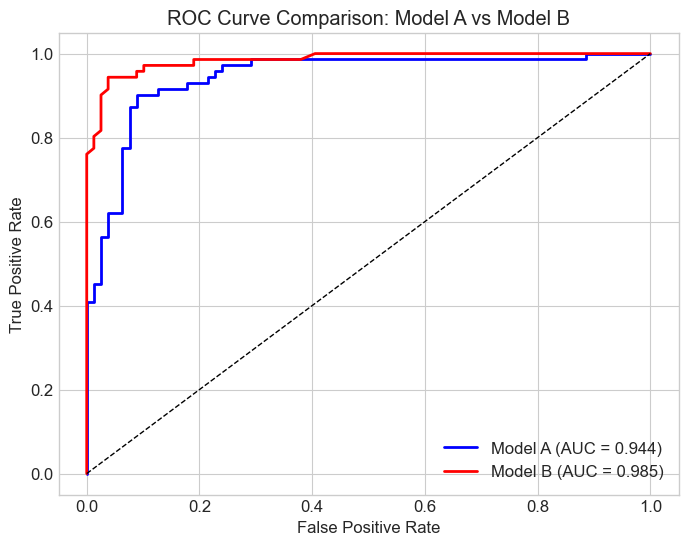


YOUR ANALYSIS:


In [21]:
# Exercise 3: Compare two models
np.random.seed(42)

# Generate sample data
X_ex3, y_ex3 = make_classification(n_samples=500, n_features=10, random_state=42)
X_train_ex3, X_test_ex3, y_train_ex3, y_test_ex3 = train_test_split(
    X_ex3, y_ex3, test_size=0.3, random_state=42
)

# Model A: Logistic Regression
model_a = LogisticRegression(random_state=42)
model_a.fit(X_train_ex3, y_train_ex3)
y_proba_a = model_a.predict_proba(X_test_ex3)[:, 1]

# Model B: Random Forest
model_b = RandomForestClassifier(n_estimators=100, random_state=42)
model_b.fit(X_train_ex3, y_train_ex3)
y_proba_b = model_b.predict_proba(X_test_ex3)[:, 1]

# Plot both ROC curves
fig, ax = plt.subplots(figsize=(8, 6))

fpr_a, tpr_a, _ = roc_curve(y_test_ex3, y_proba_a)
fpr_b, tpr_b, _ = roc_curve(y_test_ex3, y_proba_b)

auc_a = roc_auc_score(y_test_ex3, y_proba_a)
auc_b = roc_auc_score(y_test_ex3, y_proba_b)

ax.plot(fpr_a, tpr_a, 'b-', linewidth=2, label=f'Model A (AUC = {auc_a:.3f})')
ax.plot(fpr_b, tpr_b, 'r-', linewidth=2, label=f'Model B (AUC = {auc_b:.3f})')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1)

ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve Comparison: Model A vs Model B')
ax.legend()
plt.show()

# Your analysis:
print("\n" + "="*50)
print("YOUR ANALYSIS:")
print("="*50)
# Write your comparison and conclusion here:
# print("Which model is better? _____")
# print("By how much? _____")
# print("At what FPR threshold does Model B become better? _____")

### Exercise 4: Diagnose Residual Plots

Examine the residual plot below and identify:
1. What pattern do you see?
2. What problem does this indicate?
3. What would you do to fix it?

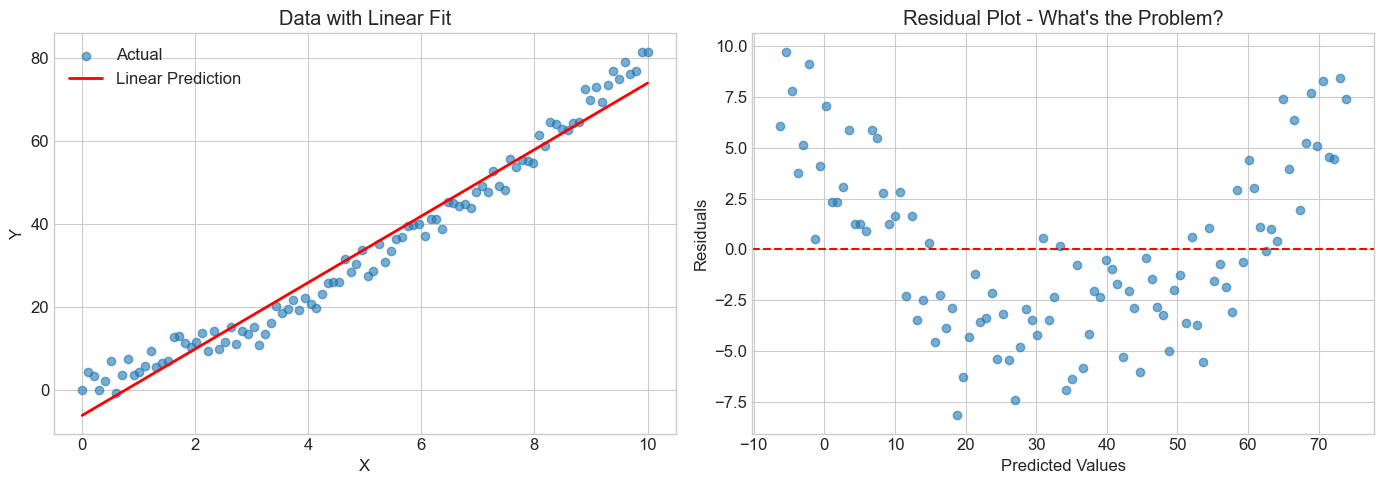


YOUR DIAGNOSIS:


In [22]:
# Exercise 4: Diagnose residuals
np.random.seed(123)

# Generate data with non-linear relationship
X_ex4 = np.linspace(0, 10, 100).reshape(-1, 1)
y_true_ex4 = 2 + 3*X_ex4.ravel() + 0.5*X_ex4.ravel()**2 + np.random.normal(0, 2, 100)

# Fit a LINEAR model (intentionally wrong)
from sklearn.linear_model import LinearRegression
lin_model = LinearRegression()
lin_model.fit(X_ex4, y_true_ex4)
y_pred_ex4 = lin_model.predict(X_ex4)

# Residuals
residuals_ex4 = y_true_ex4 - y_pred_ex4

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(X_ex4, y_true_ex4, alpha=0.6, label='Actual')
axes[0].plot(X_ex4, y_pred_ex4, 'r-', linewidth=2, label='Linear Prediction')
axes[0].set_xlabel('X')
axes[0].set_ylabel('Y')
axes[0].set_title('Data with Linear Fit')
axes[0].legend()

# Residual plot
axes[1].scatter(y_pred_ex4, residuals_ex4, alpha=0.6)
axes[1].axhline(y=0, color='r', linestyle='--')
axes[1].set_xlabel('Predicted Values')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Residual Plot - What\'s the Problem?')

plt.tight_layout()
plt.show()

print("\n" + "="*50)
print("YOUR DIAGNOSIS:")
print("="*50)
# print("1. Pattern observed: _____")
# print("2. Problem: _____")
# print("3. Solution: _____")

### Exercise 5: Evaluate Clustering

Run K-Means with different values of k and determine the optimal number of clusters using multiple metrics.

In [ ]:
# TODO: compute `k_values`, `results_ex5`, `km` from `Inertia`, `Silhouette`
# Name your result: k_values, results_ex5, km, labels

---

## Summary

### Key Takeaways

1. **Never rely on accuracy alone** - especially for imbalanced data
2. **Choose metrics based on business context** - what errors are more costly?
3. **Use multiple metrics** - they reveal different aspects of model performance
4. **Visualize your metrics** - ROC curves, residual plots, and silhouette plots tell stories
5. **Consider the threshold** - default 0.5 may not be optimal for your use case

### Quick Reference Card

| If you care about... | Use this metric |
|---------------------|------------------|
| Not missing positive cases | Recall |
| Not having false alarms | Precision |
| Balance of both | F1-Score |
| Overall discrimination | ROC-AUC |
| Imbalanced data | PR-AUC |
| Typical prediction error | RMSE |
| Robust to outliers | MAE |
| Variance explained | R-squared |
| Cluster quality | Silhouette Score |

---

**Next Steps:** Apply these metrics to your CART models (Module 04) and Deep Learning models (Module 05)!

---

## How this is used in real work

Every model review, every stakeholder conversation and every production alert threshold is this chapter. The metric you pick decides what the model optimises for, which decides who it fails. That is a design decision, not a reporting one.

## Where this goes next

Module 02 (CART), 03 (Unsupervised) and 05 (Deep Learning) all assume these metrics.